## 1. Importing Libraries

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries Imported Successfully ✅")

Libraries Imported Successfully ✅


## 2. Load Dataset

In [ ]:
df = pd.read_excel("../data/raw/online_retail_II.xlsx", sheet_name="Year 2010-2011")
print("Dataset Loaded Successfully ✅")

Dataset Loaded Successfully ✅


# Display first 5 rows & last 5 rows

In [9]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data Overview

In [10]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
541909,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [5]:
df.shape

(541910, 8)

In [6]:
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[ns]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307584,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


## 4. Exploratory Data Analysis

In [11]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(5268)

In [13]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

## 5. Data Cleaning

In [14]:
# Create a copy of original dataset
clean_df = df.copy()
print("Dataset copied successfully ✅")

Dataset copied successfully ✅


In [15]:
# Remove rows with missing Customer ID
clean_df = clean_df.dropna(subset=["Customer ID"])
print(clean_df.shape)

(406830, 8)


In [16]:
# Remove duplicate records
clean_df = clean_df.drop_duplicates()
print(clean_df.shape)

(401605, 8)


In [17]:
clean_df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [18]:
# Negative Quantity
clean_df[clean_df["Quantity"] <= 0]
# Count
(clean_df["Quantity"] <= 0).sum()

np.int64(8872)

In [19]:
# Negative Price
clean_df[clean_df["Price"] <= 0]
# Count
(clean_df["Price"] <= 0).sum()

np.int64(40)

In [ ]:
# Cancelled Orders
clean_df[clean_df["Invoice"].astype(str).str.startswith("C")]   
# Count
clean_df["Invoice"].astype(str).str.startswith("C").sum()

np.int64(8872)

## 6. Business Rule Based Data Cleaning

In [ ]:
# Remove cancelled orders (negative quantity)
clean_df = clean_df[clean_df["Quantity"] > 0]
# Remove zero or negative prices
clean_df = clean_df[clean_df["Price"] > 0]  
print("Final Dataset Shape:", clean_df.shape)

Final Dataset Shape: (392693, 8)


In [ ]:
(clean_df["Quantity"] <= 0).sum()

np.int64(0)

In [24]:
(clean_df["Price"] <= 0).sum()

np.int64(0)

In [25]:
# Create Total Amount column
clean_df["TotalAmount"] = clean_df["Quantity"] * clean_df["Price"]
# Display first 5 rows
clean_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [26]:
clean_df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [27]:
reference_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)
print(reference_date)

2011-12-10 12:50:00


# 7. RFM Analysis

In [28]:
rfm = clean_df.groupby("Customer ID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "TotalAmount": "sum"
}).reset_index()

In [30]:
# Rename Columns
rfm.columns = [
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary"
]
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [31]:
rfm.shape

(4338, 4)

# 8. Exploratory Analysis of RFM

In [32]:
# Statistical Summary
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.692230
std,1721.808492,100.014169,7.697998,8985.229676
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


In [33]:
# Check Missing Values
rfm.isnull().sum()

CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

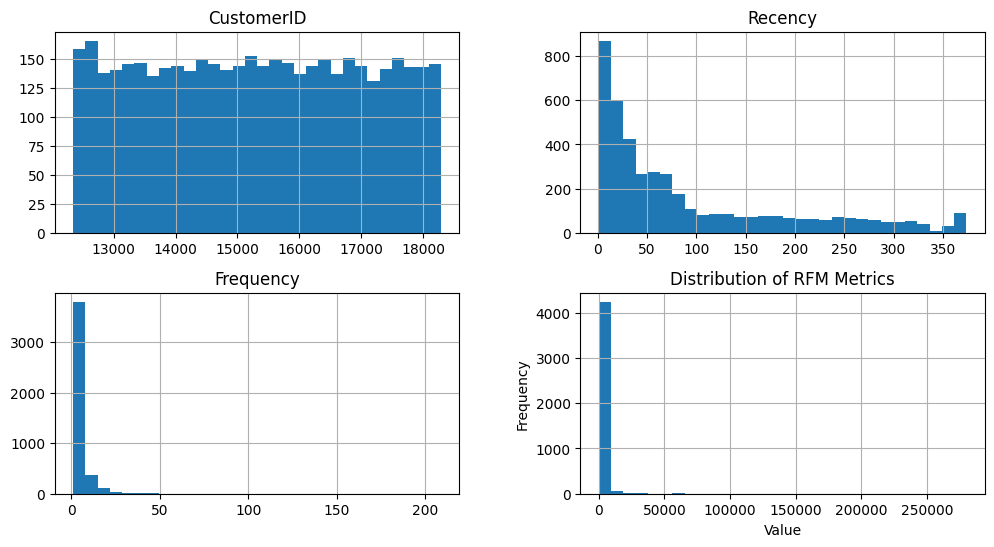

In [34]:
# Distribution
rfm.hist(figsize=(12,6), bins=30)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of RFM Metrics")
plt.show()

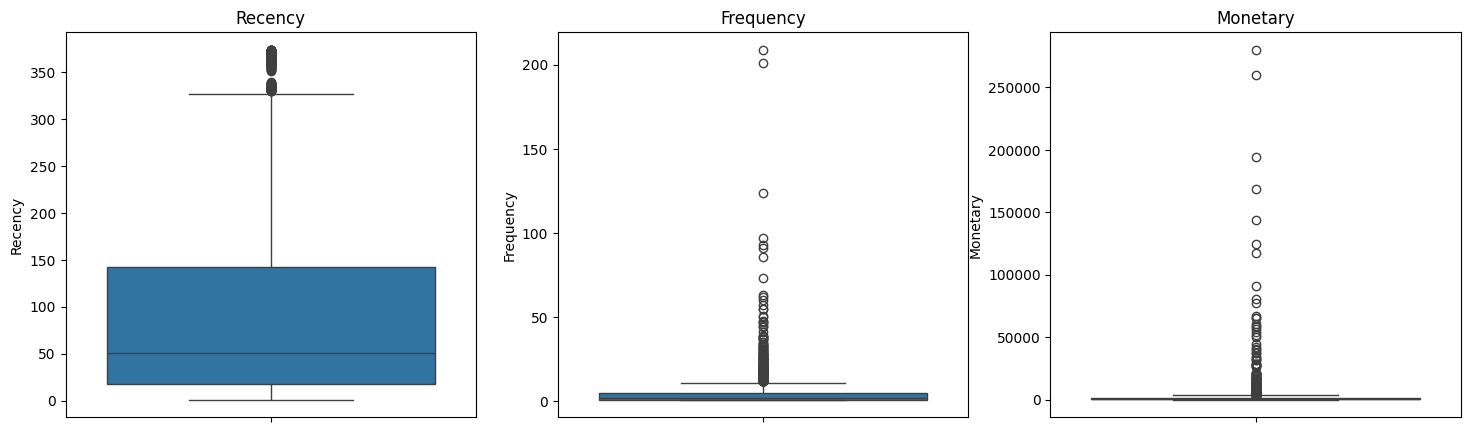

In [ ]:
# Boxplots
fig, axes = plt.subplots(1,3, figsize=(18,5))
sns.boxplot(y=rfm["Recency"], ax=axes[0])
axes[0].set_title("Recency")
sns.boxplot(y=rfm["Frequency"], ax=axes[1])
axes[1].set_title("Frequency")
sns.boxplot(y=rfm["Monetary"], ax=axes[2])
axes[2].set_title("Monetary")
plt.show()

# 9. Feature Transformation

In [ ]:
# Log Transformation
rfm_log = rfm.copy()
rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])
rfm_log.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,5.789960,0.693147,11.253955
1,12347.0,1.098612,2.079442,8.368925
2,12348.0,4.330733,1.609438,7.494564
3,12349.0,2.995732,0.693147,7.472245
4,12350.0,5.739793,0.693147,5.815324


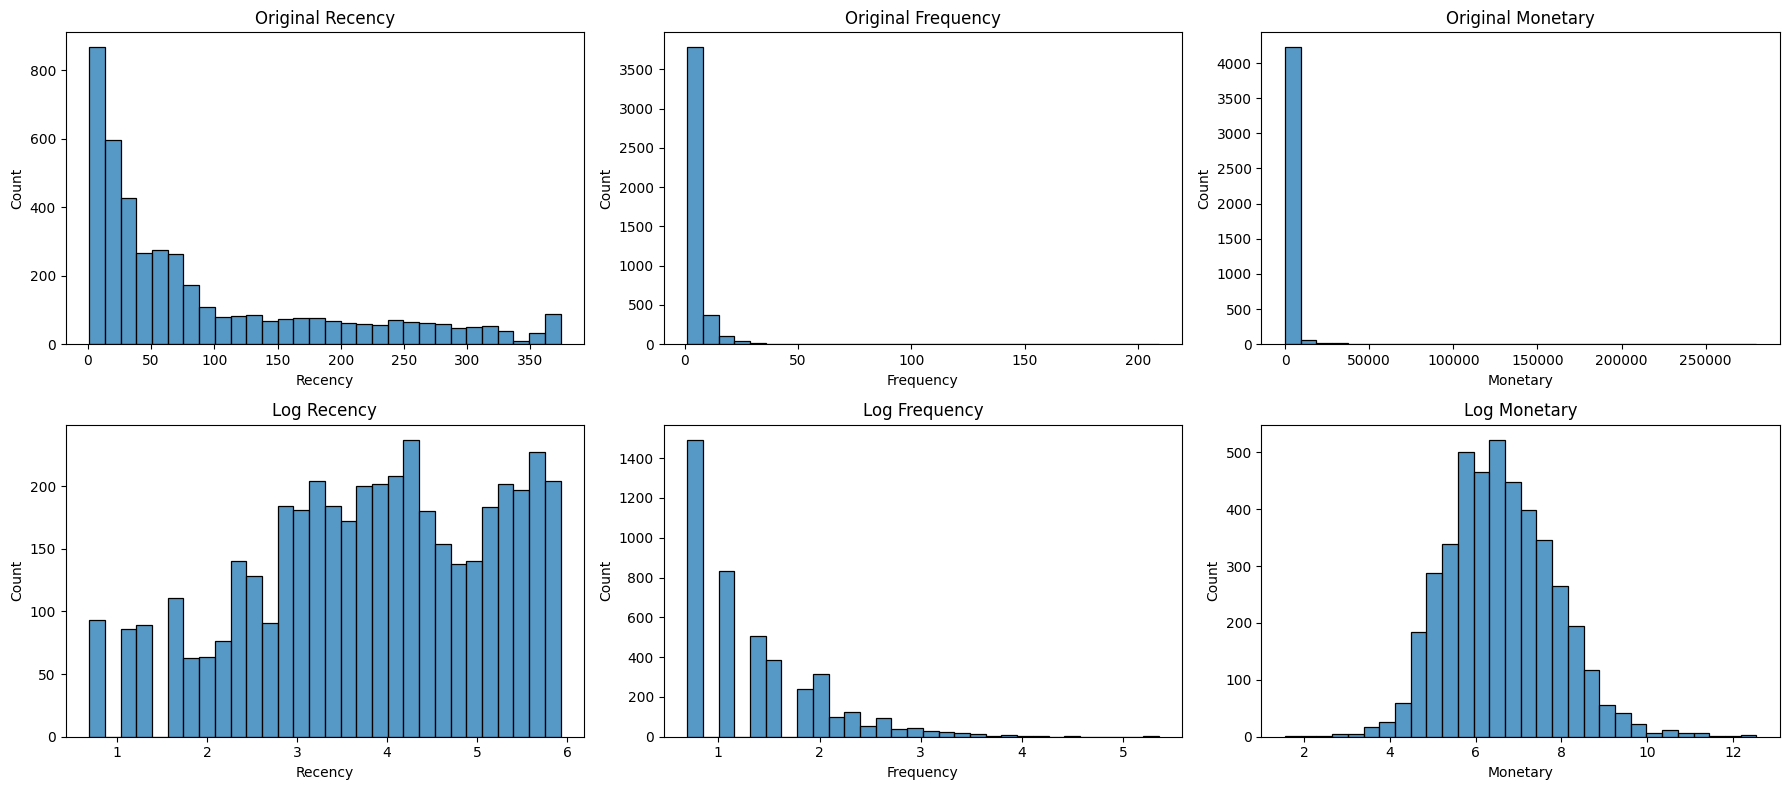

In [37]:
# Compare Before & After
fig, axes = plt.subplots(2,3, figsize=(18,8))

# Original
sns.histplot(rfm["Recency"], ax=axes[0,0], bins=30)
axes[0,0].set_title("Original Recency")

sns.histplot(rfm["Frequency"], ax=axes[0,1], bins=30)
axes[0,1].set_title("Original Frequency")

sns.histplot(rfm["Monetary"], ax=axes[0,2], bins=30)
axes[0,2].set_title("Original Monetary")

# Log Transformed
sns.histplot(rfm_log["Recency"], ax=axes[1,0], bins=30)
axes[1,0].set_title("Log Recency")

sns.histplot(rfm_log["Frequency"], ax=axes[1,1], bins=30)
axes[1,1].set_title("Log Frequency")

sns.histplot(rfm_log["Monetary"], ax=axes[1,2], bins=30)
axes[1,2].set_title("Log Monetary")

plt.tight_layout()
plt.show()

# 10. Feature Scaling

In [39]:
# Create Feature Matrix
features = rfm_log[["Recency", "Frequency", "Monetary"]]

In [40]:
# Scale Features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [41]:
# Convert to DataFrame
scaled_df = pd.DataFrame(scaled_features, columns=features.columns)
scaled_df.head()

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707710
1,-2.038734,1.074425,1.414899
2,0.373104,0.386304,0.720020
3,-0.623086,-0.955214,0.702283
4,1.424558,-0.955214,-0.614517


In [42]:
# Verify Scaling
scaled_df.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.68
50%,0.09,-0.36,-0.07
75%,0.84,0.65,0.66
max,1.56,5.86,4.73


# 11. Elbow Method

In [ ]:
# Calculate WCSS
wcss = []
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_df)
    wcss.append(kmeans.inertia_)

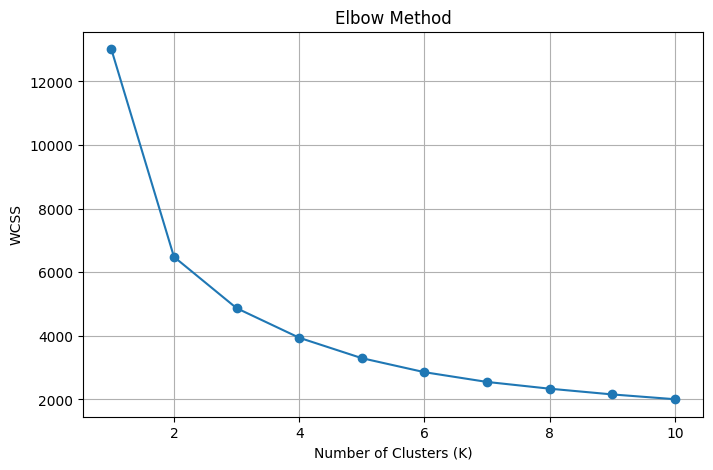

In [45]:
# Plot Elbow Curve
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

# 12. K-Means Clustering

In [46]:
# Train Model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
kmeans.fit(scaled_df)

,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [47]:
# Assign Cluster Labels
rfm["Cluster"] = kmeans.labels_

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,3
1,12347.0,2,7,4310.00,0
2,12348.0,75,4,1797.24,3
3,12349.0,19,1,1757.55,2
4,12350.0,310,1,334.40,1


In [48]:
# Check Cluster Counts
rfm["Cluster"].value_counts().sort_index()

Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

In [49]:
# Cluster Centers
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=["Recency", "Frequency", "Monetary"]
)

centroids

,Recency,Frequency,Monetary
0,2.166077,2.482824,8.360613
1,5.012938,0.813794,5.584875
2,2.677080,1.105481,6.106479
3,4.028655,1.563321,7.248654


In [50]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "CustomerID": "count"
}).rename(columns={"CustomerID": "Customers"})

cluster_summary.round(2)

,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.34,837
3,71.64,4.08,1801.78,1166


# 13. Customer Segment Naming

In [51]:
segment_names = {
    0: "VIP Customers",
    1: "At Risk Customers",
    2: "New Customers",
    3: "Loyal Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,3,Loyal Customers
1,12347.0,2,7,4310.00,0,VIP Customers
2,12348.0,75,4,1797.24,3,Loyal Customers
3,12349.0,19,1,1757.55,2,New Customers
4,12350.0,310,1,334.40,1,At Risk Customers


In [52]:
# Segment Distribution
rfm["Segment"].value_counts()

Segment
At Risk Customers    1622
Loyal Customers      1166
New Customers         837
VIP Customers         713
Name: count, dtype: int64

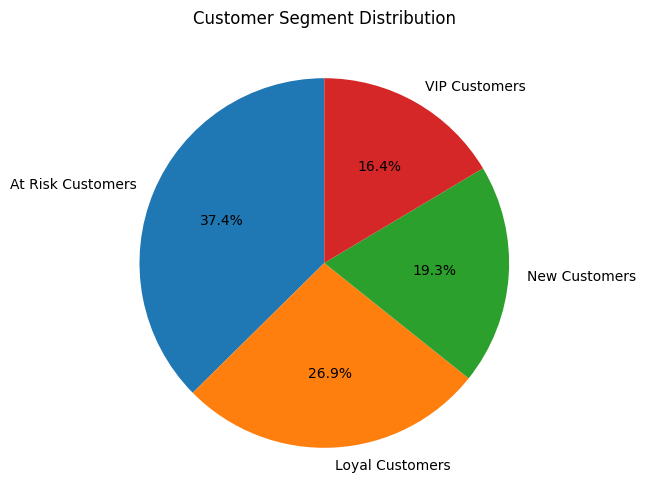

In [54]:
# Visualization Time
segment_counts = rfm["Segment"].value_counts()
plt.figure(figsize=(8,6))
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Customer Segment Distribution")
plt.show()

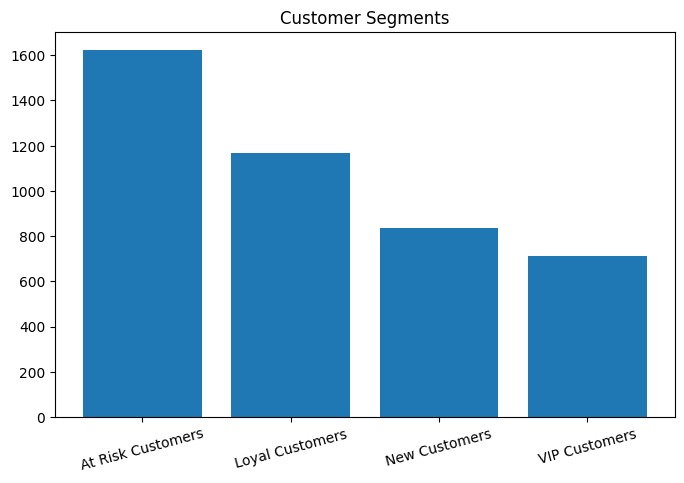

In [56]:
# Bar Chart
plt.figure(figsize=(8,5))
plt.bar(
    rfm["Segment"].value_counts().index,
    rfm["Segment"].value_counts().values
)
plt.title("Customer Segments")
plt.xticks(rotation=15)
plt.show()